In [14]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt


In [15]:
!python smaparsing.py


sp500 1950-01-03 2026-10-15 19319  - duplicates: 0  - NaN cells: 0  - longest gap (in days): 7.0
/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/smaparsing.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"sma_{length}"] = df["Close"].rolling(window=length).mean() # calculates mean of rolling window of length and adds it as a new column to the dataframe
/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/smaparsing.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"sma_{length}"] = df["Cl

In [88]:
original_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/raw")

processed_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/processed")



In [89]:
results_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/results")
results_data_path.mkdir(parents=True, exist_ok=True)    

In [90]:
# sorry for excessive quotations, trying to quit lazy Ai code writing habits

In [91]:
PAYMENT = 500 # per month ( unrealistic, obviously. figurative value not accounting for inflation)
INTEREST_RATE = 0.03 # 3% interest rate for cash in the bank
START_DATE = "1986-01-01"

DIV_YIELD = {   # note: these are approximate values and may vary over time
    "sp500": 0.02, "nasdaq_comp": 0.01, "nasdaq100": 0.01, "ftse100": 0.04,
    "nikkei": 0.01, "dax": 0.0, "cac40": 0.03, "hang_seng": 0.03, "shanghai": 0.02,
    "euro_stoxx": 0.03, "nifty": 0.013, "dow_jones": 0.02,
}                                                                                        # dictionaries

STRATEGIES = {"DCA": None, "SMA50": "sma_50", "SMA100": "sma_100", "SMA200": "sma_200"}

In [92]:
def simulate(df, sma_timeframe, dividend_yield, values=None): # function can receive a values argument, but it doesn't have to
    dates = df.index.tolist()
    closes = df["Close"].tolist()
    if sma_timeframe is not None:
        smas = df[sma_timeframe].tolist() # every days calculated sma in a list

    valid = df[(df.index >= START_DATE) & df["sma_200"].notna()]  # first day with sma_200 available. filtered dataframe with only "valid" rows
    start = df.index.get_loc(valid.index[0]) # first column where in valid. this will iterate for all datasets not one df with all indexes one per df
    end = df.index.get_loc(valid.index[-1])


    cash = 0
    units = 0
    units_bought = 0
    total_invested_stocks = 0
    last_sma_value_when_buying = 0
    total_invested = 0
    last_value_bought = 0
    n_buys = 0
    next_payment = dates[start].replace(day=1) + pd.DateOffset(months=1)       # next_payment = dates[start] + pd.Timedelta(days=(7 - dates[start].weekday()) % 7) for weekly simulations



    for i in range(start, end + 1):
        days = (dates[i] - dates[i - 1]).days # days between i row and i-1 row as int (.days returns int). used for interest/dividend calculations (since there are not rows for all days)
        cash = cash * (1 + INTEREST_RATE) ** (days / 365)
        units = units * (1 + dividend_yield) ** (days / 365)

        while next_payment <= dates[i]: # checks if payday has come
            cash += PAYMENT
            total_invested += PAYMENT # total invested is both cash and stock
            next_payment += pd.DateOffset(months=1) # next_payment += pd.Timedelta(days=7) for weekly simulations

        if sma_timeframe is None:
            signal = True       # if no sma_timeframe is provided, the signal is always True (DCA strategy)
        else:
            signal = closes[i - 1] < smas[i - 1] # if the previous day's close is below the previous day's sma_x, then the signal is True (buy signal)

        if cash > 0 and signal == True: # if there is cash available and the signal is True, then buy
            units = units + cash / closes[i-1]
            units_bought += cash / closes[i-1]
            total_invested_stocks += cash
            n_buys += 1
            cash = 0
            last_value_bought = closes[i-1]
            if sma_timeframe is not None:
                last_sma_value_when_buying = smas[i - 1]

        if values is not None:
            values.append(units * closes[i] + cash)   # so that we can plot the value of the portfolio over time later is not doing much here

    final_value = units * closes[-1] + cash
    keys = {
        "strategy_simulated": sma_timeframe if sma_timeframe is not None else "DCA",
        "start_date": dates[start].date(),
        "end_date": dates[-1].date(),
        "total_invested": total_invested,
        "total_invested_stocks": total_invested_stocks,
        "final_value": final_value,
        "total_return_pct": (final_value / total_invested - 1) * 100,
        "units": units,
        "avg_price": total_invested_stocks / units_bought if units_bought > 0 else None,
        "leftover_cash": cash,
        "n_buys": n_buys,
        "last_close": closes[i],
        "last_value_bought": last_value_bought,
        "last_sma_value_when_buying": last_sma_value_when_buying
    }

    return pd.DataFrame([keys], index=[keys["strategy_simulated"]]) # returns df with all those columns and index is the strategy

In [93]:
def run_index_simulator(df, name):
    results = [] # always need to maintain empty list to receive att
    for strategy, sma_timeframe in STRATEGIES.items():
        results.append(simulate(df, sma_timeframe, DIV_YIELD[name]))

        
    table = pd.concat(results)
    table.insert(0, "index", name)   # first column holds the index name
    return table

In [94]:
df = pd.read_csv(processed_data_path / "sp500_processed.csv", index_col=0, parse_dates=True)


In [95]:
run_index_simulator(df,"sp500")

,index,strategy_simulated,start_date,end_date,total_invested,total_invested_stocks,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys,last_close,last_value_bought,last_sma_value_when_buying
DCA,sp500,DCA,1986-01-02,2026-10-15,244500,244500.000000,4.146553e+06,1595.931645,535.449472,833.918779,0.000000,489,7744.060059,7651.540039,0.000000
sma_50,sp500,sma_50,1986-01-02,2026-10-15,244500,244626.410333,4.136387e+06,1591.773631,534.072041,835.413216,500.567203,320,7744.060059,7591.700195,7603.864209
sma_100,sp500,sma_100,1986-01-02,2026-10-15,244500,242805.008271,4.117207e+06,1583.929404,531.269823,832.470124,3021.972514,245,7744.060059,6528.520020,6811.818491
sma_200,sp500,sma_200,1986-01-02,2026-10-15,244500,244437.143541,4.084846e+06,1570.693574,527.090930,841.863571,3021.972514,176,7744.060059,6528.520020,6638.858091


In [96]:
all_tables = []
for name in DIV_YIELD:
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True)
    all_tables.append(run_index_simulator(df, name))

all_tables = pd.concat(all_tables)


display(all_tables)
all_tables.to_csv(results_data_path / "results.csv", index=False)

,index,strategy_simulated,start_date,end_date,total_invested,total_invested_stocks,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys,last_close,last_value_bought,last_sma_value_when_buying
DCA,sp500,DCA,1986-01-02,2026-10-15,244500,244500.000000,4.146553e+06,1595.931645,535.449472,833.918779,0.000000,489,7744.060059,7651.540039,0.000000
sma_50,sp500,sma_50,1986-01-02,2026-10-15,244500,244626.410333,4.136387e+06,1591.773631,534.072041,835.413216,500.567203,320,7744.060059,7591.700195,7603.864209
sma_100,sp500,sma_100,1986-01-02,2026-10-15,244500,242805.008271,4.117207e+06,1583.929404,531.269823,832.470124,3021.972514,245,7744.060059,6528.520020,6811.818491
sma_200,sp500,sma_200,1986-01-02,2026-10-15,244500,244437.143541,4.084846e+06,1570.693574,527.090930,841.863571,3021.972514,176,7744.060059,6528.520020,6638.858091
DCA,nasdaq_comp,DCA,1986-01-02,2026-10-15,244500,244500.000000,6.688181e+06,2635.452318,250.371526,1336.460373,0.000000,489,26713.025391,26861.060547,0.000000
sma_50,nasdaq_comp,sma_50,1986-01-02,2026-10-15,244500,244618.487521,6.623347e+06,2608.935270,247.925724,1348.999828,500.567203,312,26713.025391,25981.570312,26051.114375
sma_100,nasdaq_comp,sma_100,1986-01-02,2026-10-15,244500,245281.349671,6.632515e+06,2612.684991,248.268930,1350.420798,500.567203,242,26713.025391,25981.570312,25996.284121
sma_200,nasdaq_comp,sma_200,1986-01-02,2026-10-15,244500,244438.680604,6.633267e+06,2612.992445,248.202682,1344.881463,3021.972514,180,26713.025391,21590.630859,22316.485420
DCA,nasdaq100,DCA,1986-07-16,2026-10-15,241500,241500.000000,1.292168e+07,5250.592392,431.649385,776.160869,0.000000,483,29935.593750,30408.500000,0.000000
sma_50,nasdaq100,sma_50,1986-07-16,2026-10-15,241500,241585.968356,1.280126e+07,5200.727936,427.609938,783.251402,500.567203,314,29935.593750,29077.220703,29225.853281


In [97]:
from matplotlib.ticker import StrMethodFormatter

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

curves = {}  # curves[name][strategy] = portfolio value for every day
finals = {}  # finals[name][strategy] = final value
dates = {}   # dates[name] = x axis dates

for name in DIV_YIELD:
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True)
    df = df.dropna(subset=["Close"])
    curves[name] = {}
    finals[name] = {}
    for strategy, sma_col in STRATEGIES.items():
        values = []
        result = simulate(df, sma_col, DIV_YIELD[name], values)
        curves[name][strategy] = values
        finals[name][strategy] = result["final_value"].iloc[0]
    dates[name] = df.index[-len(values):]  # same length for every strategy

names = list(DIV_YIELD)
n_rows = (len(names) + 2) // 3  # 3 charts per row, grows if you add indices

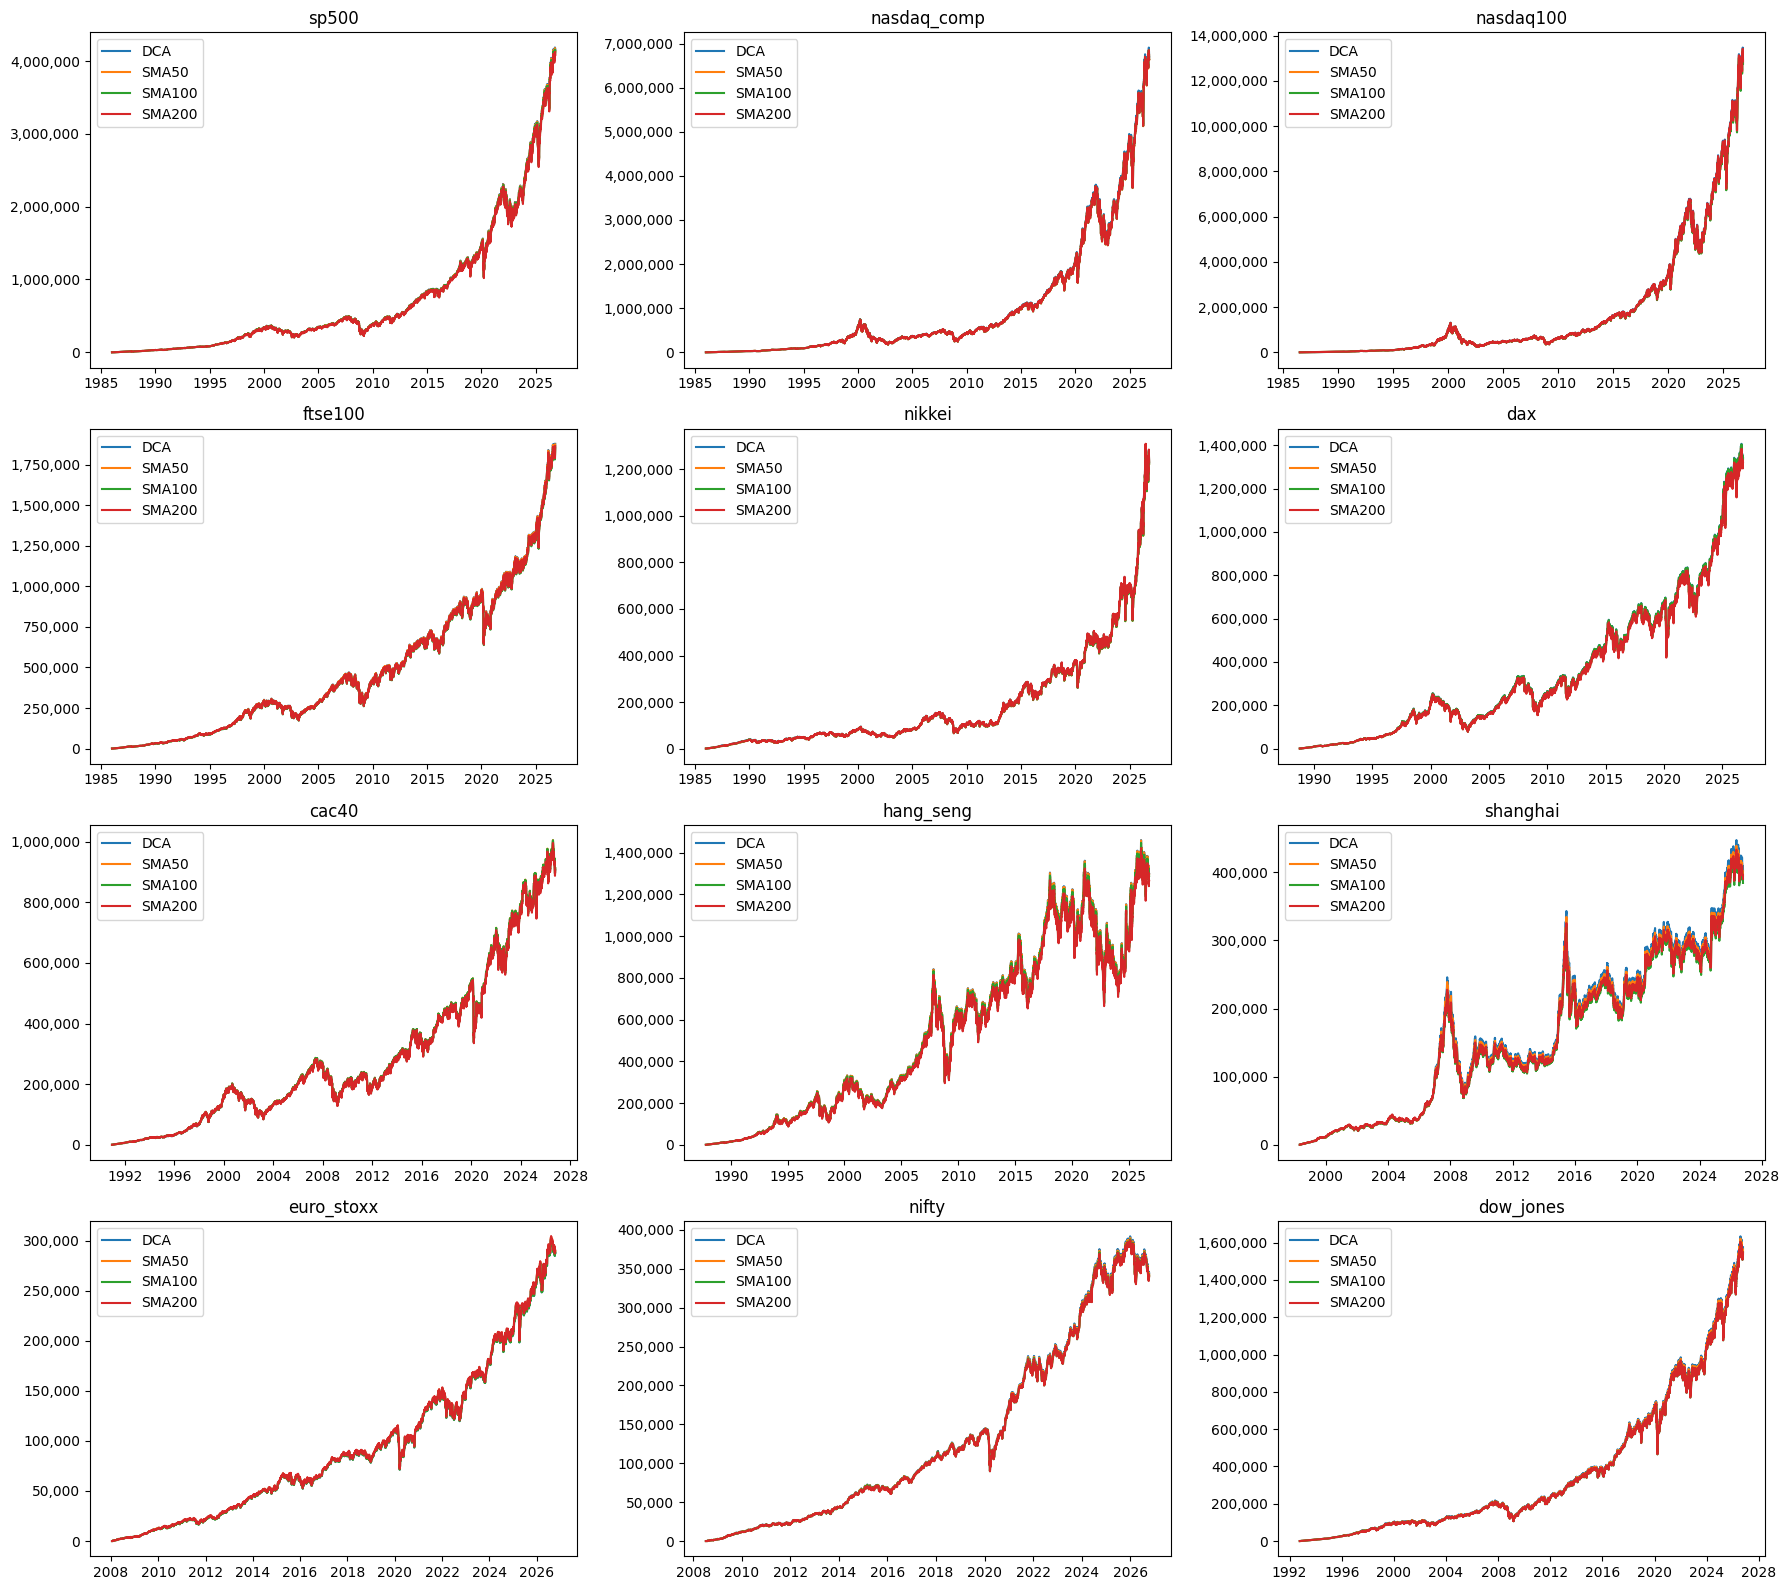

In [98]:
fig, axes = plt.subplots(n_rows, 3, figsize=(18, 4 * n_rows))
axes = axes.flatten()
for i in range(len(names)):
    ax = axes[i]
    for strategy in STRATEGIES:
        ax.plot(dates[names[i]], curves[names[i]][strategy], label=strategy)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_title(names[i])
    ax.legend()
plt.tight_layout()
plt.show()

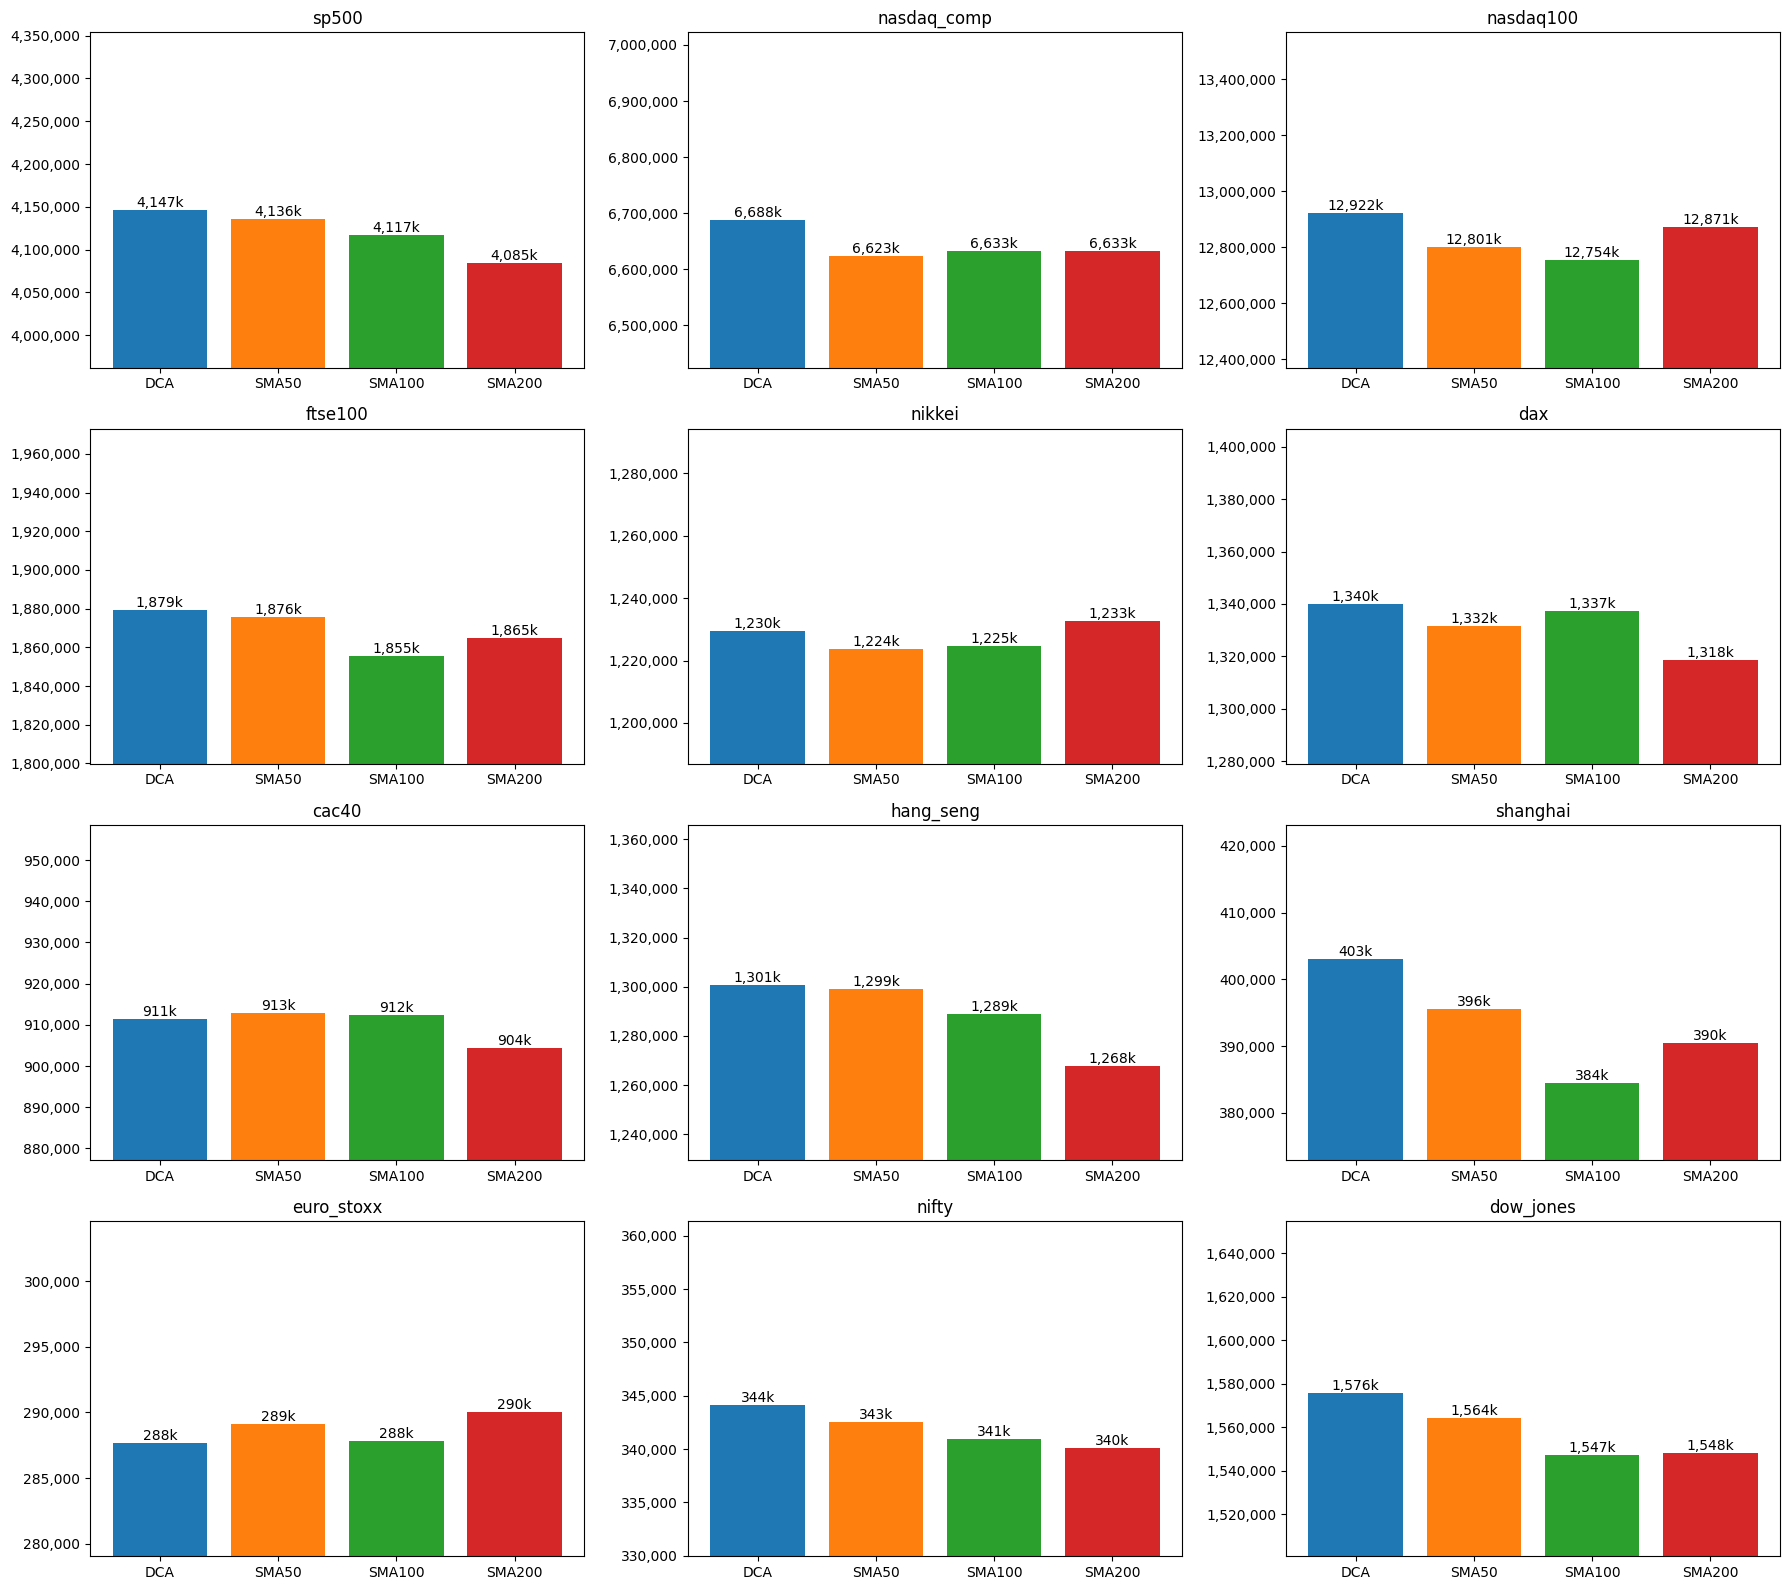

In [99]:
fig, axes = plt.subplots(n_rows, 3, figsize=(18, 4 * n_rows))
axes = axes.flatten()
for i in range(len(names)):
    ax = axes[i]
    final_values = []
    labels = []
    for strategy in STRATEGIES:
        value = finals[names[i]][strategy]
        final_values.append(value)
        labels.append(f"{value / 1000:,.0f}k")
    bars = ax.bar(list(STRATEGIES), final_values, color=colors)
    ax.bar_label(bars, labels=labels)
    ax.set_ylim(bottom=min(final_values) * 0.97)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_title(names[i])
plt.tight_layout()
plt.show()

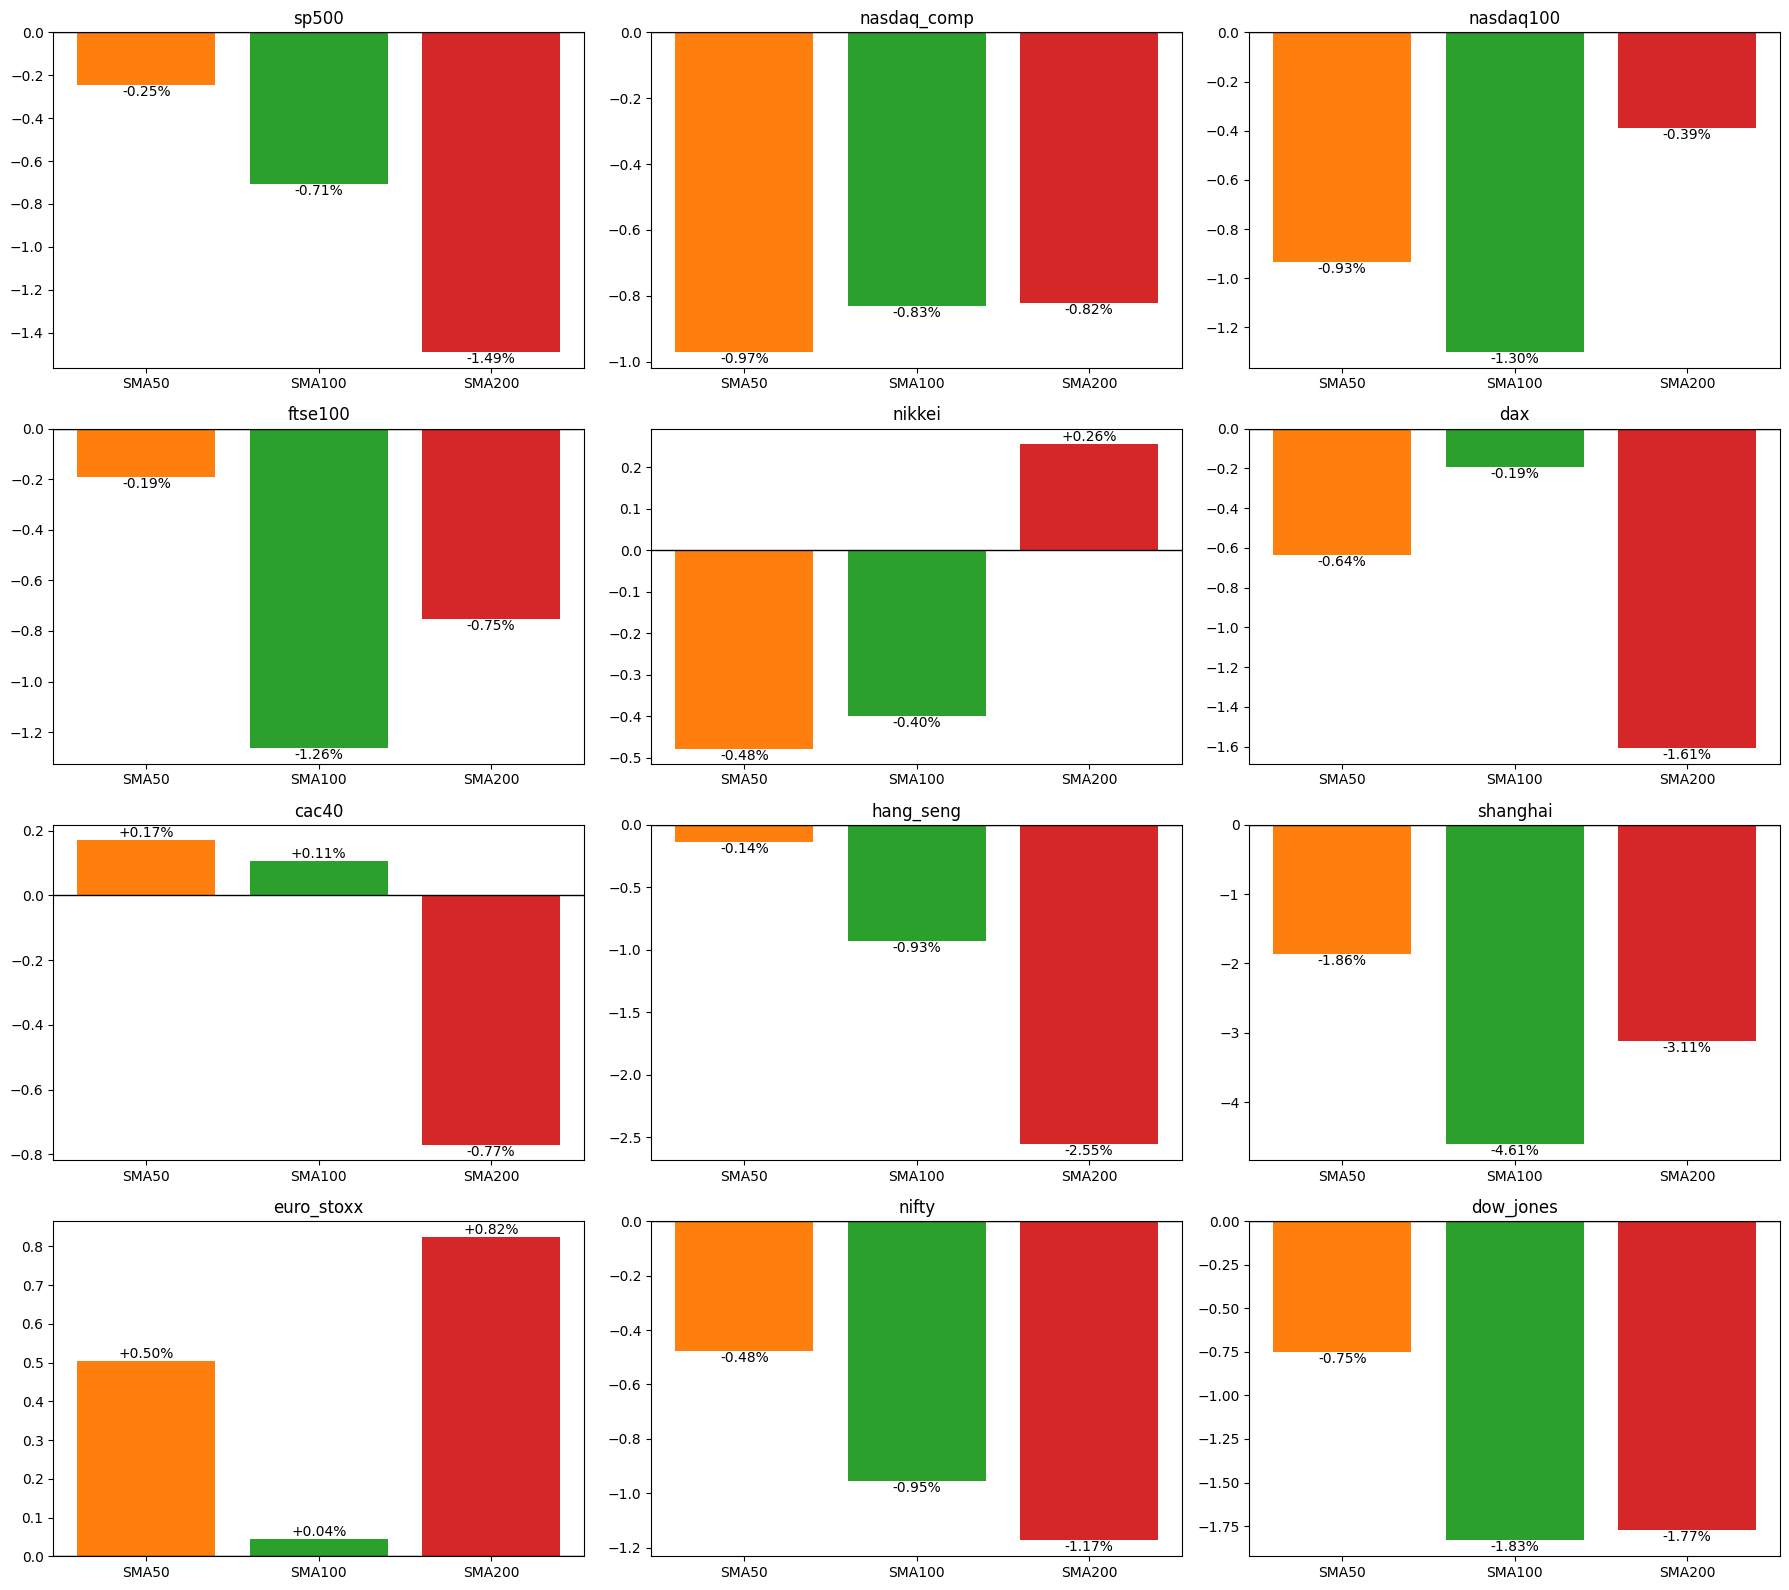

In [100]:
fig, axes = plt.subplots(n_rows, 3, figsize=(18, 4 * n_rows))
axes = axes.flatten()
for i in range(len(names)):
    ax = axes[i]
    labels = []
    diffs = []
    texts = []
    for strategy in STRATEGIES:
        if strategy != "DCA":
            diff = (finals[names[i]][strategy] / finals[names[i]]["DCA"] - 1) * 100
            labels.append(strategy)
            diffs.append(diff)
            texts.append(f"{diff:+.2f}%")
    bars = ax.bar(labels, diffs, color=colors[1:])
    ax.bar_label(bars, labels=texts)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(names[i])
plt.tight_layout()
plt.show()

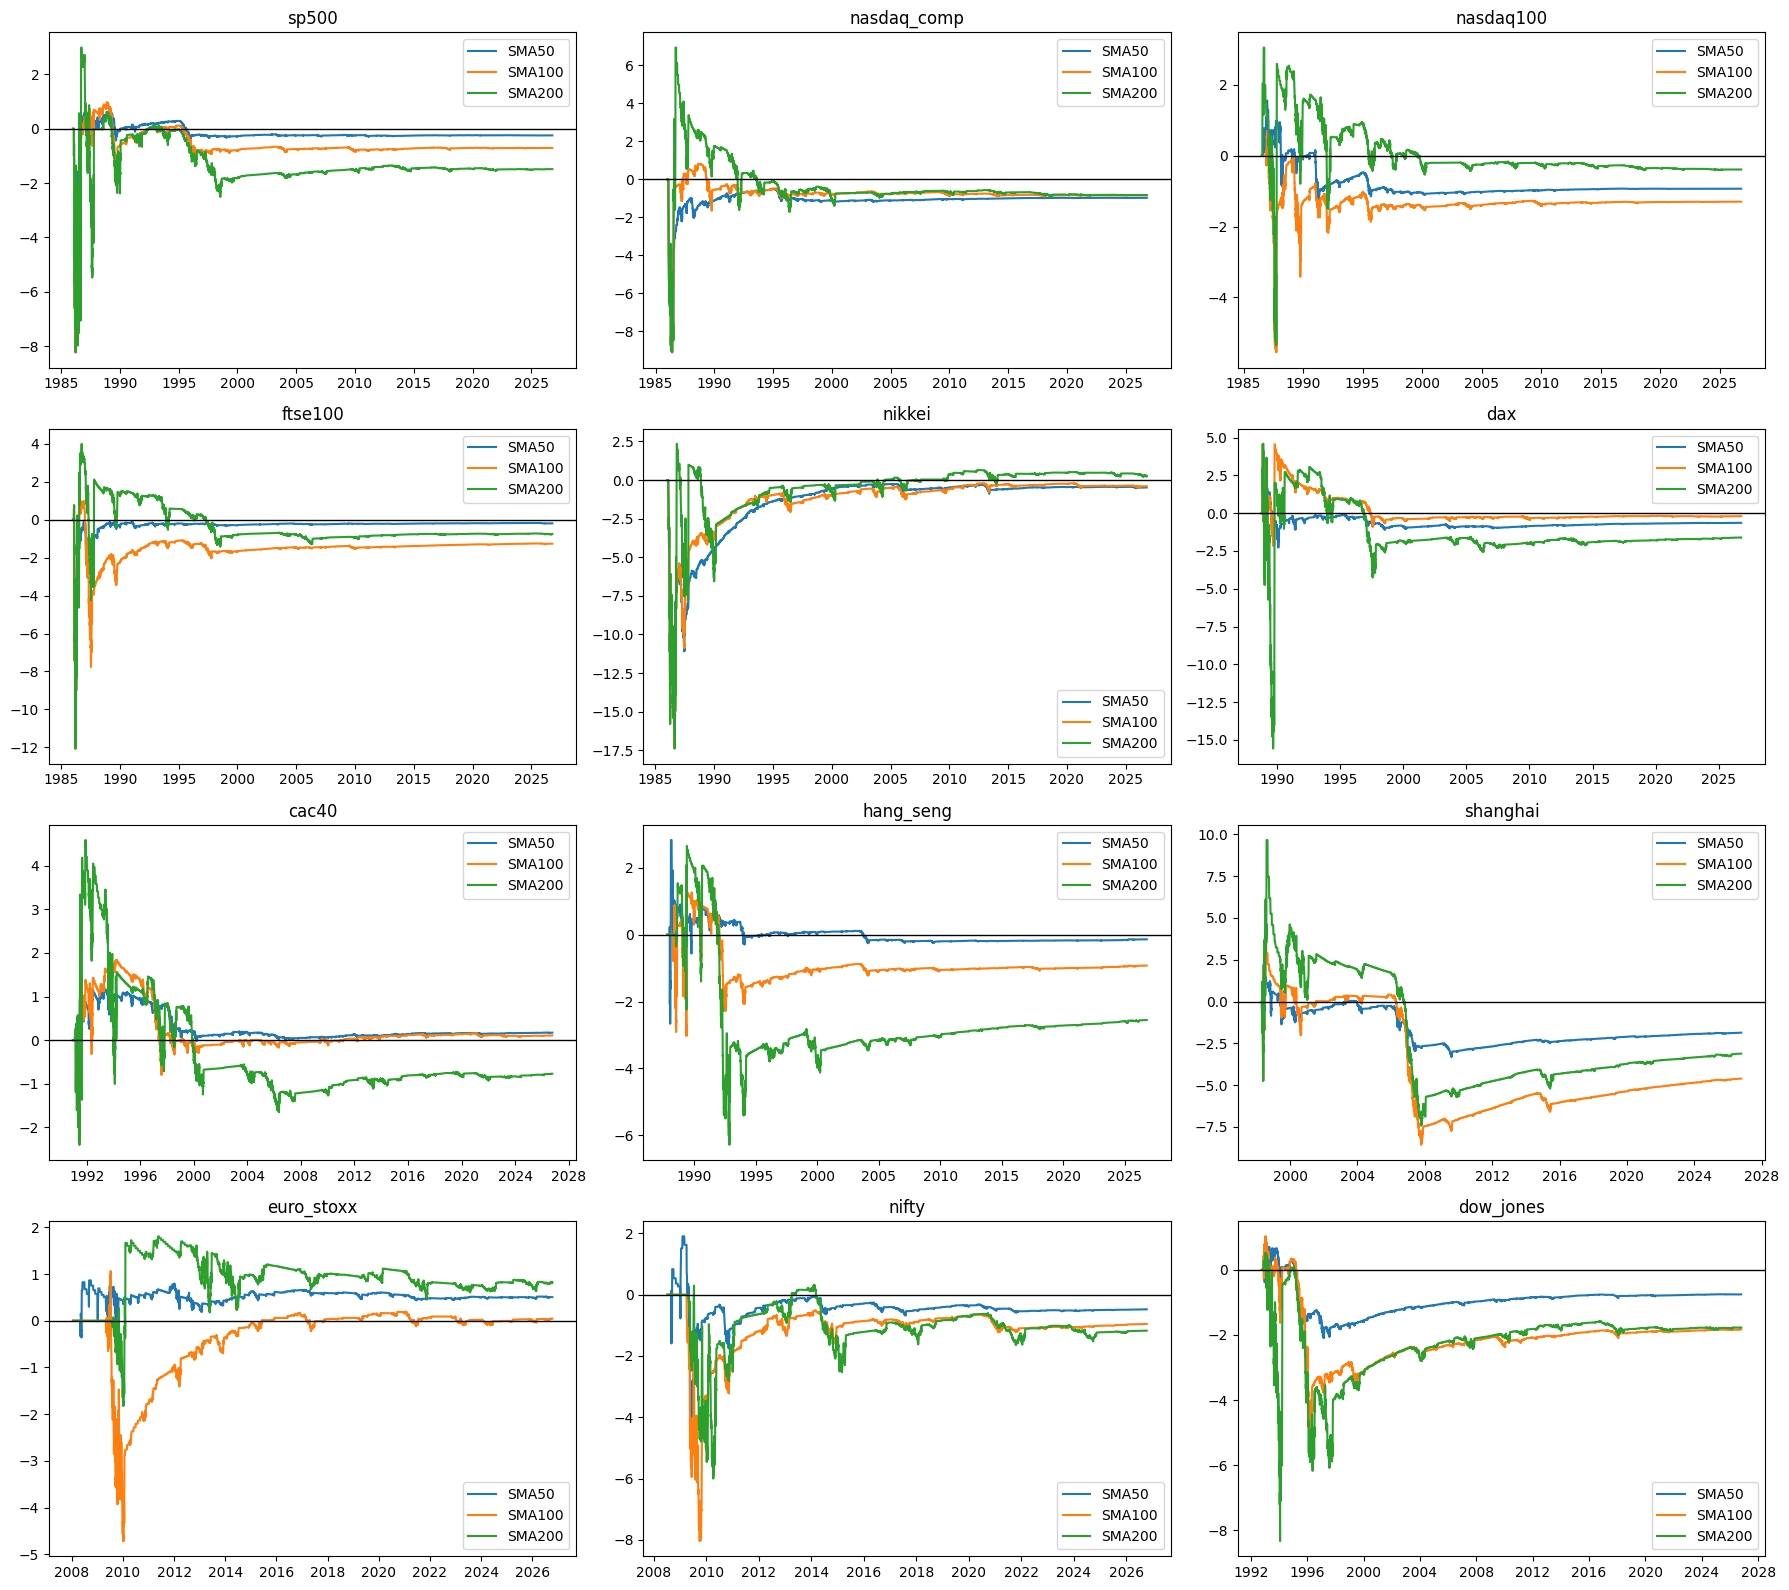

In [104]:
fig, axes = plt.subplots(n_rows, 3, figsize=(18, 4 * n_rows))
axes = axes.flatten()
for i in range(len(names)):
    ax = axes[i]
    dca = curves[names[i]]["DCA"]
    for strategy in STRATEGIES:
        if strategy != "DCA":
            vals = curves[names[i]][strategy]
            diff = []
            for k in range(len(vals)):
                if dca[k] == 0:
                    diff.append(0)  # no money yet, both are 0
                else:
                    diff.append((vals[k] / dca[k] - 1) * 100)
            ax.plot(dates[names[i]], diff, label=strategy)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(names[i])
    ax.legend()
plt.tight_layout()
plt.show()